<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Uma introdução as Redes Neurais Artificiais</div>
  <div style="font-size: 18px;"><strong>Prof. Dr. E.R.Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2025</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Sumário**

- [1. Cálculo de um neurônio e implementação em Python](#secao-1)
- [2. Combinando neurônios em uma rede neural](#secao-2)
- [3. Treinamento de redes neurais: dados e função de perda](#secao-3)
- [4. Gradientes e atualização de pesos](#secao-4)
- [5. Aplicações em Engenharia Química](#secao-5)



<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; text-align:left; color:#003366; font-size:22px; font-weight:bold; border-radius:8px; padding:15px 20px; margin-top:20px;">1. Cálculo de um neurônio e implementação em Python</div>

**Exemplo de cálculos usando entradas (*inputs*) e pesos (*weights*).**

__Exemplo de cálculo de neurônio__:

Suponha que temos um neurônio com 2 entradas que utiliza a __função de ativação sigmóide__ e possui os seguintes parâmetros:

$$ w = [2, -1] $$

$$ b = 1 $$

Aqui, $w=[2,-1]$ significa $w_1=2$ e $w_2=-1$ de forma vetorial.  
Vamos fornecer ao neurônio a entrada:

$$ x = [1, 4] $$

Usando o __produto escalar__, calculamos a soma ponderada:

\begin{align*}
(w \cdot x) + b &= (w_1 \cdot x_1) + (w_2 \cdot x_2) + b \\
&= 2 \cdot 1 + (-1) \cdot 4 + 1 \\
&= -1
\end{align*}

Agora, substituímos este valor na função sigmóide:

\begin{equation}
y = f(w \cdot x + b) = f(-1)
\end{equation}

Substituindo na sigmóide:

\begin{align*}
S &= \frac{1}{1 + e^{-z}} \\
S &= \frac{1}{1 + e^{-(-1)}} \\
S &= \frac{1}{1 + e^1} \\
S &\approx 0.269
\end{align*}

Para as entradas $x=[1,4]$, a saída calculada do neurônio é aproximadamente **0,269**. A propagação das entradas até a saída é denominada *feedforward*. A seguir, vamos reproduzir esse resultado computacionalmente, declarando as variáveis e aplicando a função sigmoide.


In [13]:
import numpy as np

# ----------------------------
# Declarando as variáveis
# ----------------------------

# Entradas do neurônio
x1, x2 = 1, 4

# Bias
b = 1

# Pesos
w1, w2 = 2, -1

# ----------------------------
# Cálculo da soma ponderada
# ----------------------------
soma = w1 * x1 + w2 * x2 + b

# ----------------------------
# Aplicando a função sigmóide
# ----------------------------
sigmoid = 1 / (1 + np.exp(-soma))

# ----------------------------
# Mostrando o resultado
# ----------------------------
print('O valor da sigmoide: {:.3f}'.format(sigmoid))

O valor da sigmoide: 0.269


Agora vamos fazer uma implementação mais elaborada.

In [14]:
import numpy as np

def sigmoid(x):
    # Função de ativação sigmóide
    return 1 / (1 + np.exp(-x))

class Neuron:
    def __init__(self, weights, bias):
        self.weights = weights
        self.bias = bias

    def feedforward(self, inputs): 
        # Produto escalar dos pesos com a entrada + bias, aplicado na sigmóide
        total = np.dot(self.weights, inputs) + self.bias
        return sigmoid(total)

# ----------------------------
# Valores do neurônio
# ----------------------------
weights = np.array([2, -1])  # w1 = 2, w2 = -1
bias = 1                     # b = 1
n = Neuron(weights, bias)

# Entrada
x = np.array([1, 4])         # x1 = 1, x2 = 4

# Resultado
print('O valor da sigmoide: {:.3f}'.format(n.feedforward(x)))

O valor da sigmoide: 0.269


Observe que o resultado é o mesmo dos cálculo anterior.

__Explicação do código acima__.

1. O que é uma __classe__ em Python?

Uma classe é como um molde ou "modelo" para criar objetos. No exemplo acima, temos:

```python
class Neuron:

```
Você está criando um molde para representar um neurônio artificial.

2. O que é o `__init__`?

 O  `__init_` é um método especial chamado de __construtor__. Ele é automaticamente chamado quando você cria um novo __objeto__ a partir da __classe__.  

 ```python
def __init__(self, weights, bias):
```
Esse método inicializa os atributos do __objeto__ — ou seja, define os valores que ele vai ter.

3. O que é `self`?

O `self` representa o próprio __objeto__ que está sendo criado. Com ele, você guarda valores dentro do objeto, para usá-los depois.

4. Explicando a expressão completa:

 ```python
class Neuron:
    def __init__(self, weights, bias):
        self.weights = weights
        self.bias = bias
```

 - `weight` e `bias` são parâmetros passados ao criar o neurônio.
 - `self.weights` e `self.bias` são atributos internos do objeto que armazenam esses valores

__Exemplo básico de uso__:

<div style="background-color:#f1faff; border-left:6px solid #0074B7; text-align:left; color:#003366; font-size:16px; border-radius:8px; padding:15px 20px; margin-top:20px;">
  <strong>Atenção:</strong> Veja abaixo um exemplo de classe com método <code>__init__</code> e uso de <code>self</code>:
</div>

```python
class Neuron:
    def __init__(self, weights, bias):
        self.weights = weights
        self.bias = bias

    def feedforward(self, inputs):
        total = sum(w * i for w, i in zip(self.weights, inputs)) + self.bias
        return total

n = Neuron(weights=[0.5, -1.5], bias=2.0)
output = n.feedforward([1.0, 2.0])
print("Saída:", output)
```


Vamos rodar esse código em uma clélula de códigos com a impressão dos valores armazenados em __total__.

In [15]:
class Neuron:
    def __init__(self, weights, bias):
        self.weights = weights
        self.bias = bias

    def feedforward(self, inputs):
        total = sum(w * i for w, i in zip(self.weights, inputs)) + self.bias
        print("Total dentro da função:", total)  # Apenas para depuração
        return total

n = Neuron(weights=[0.5, -1.5], bias=2.0)
output = n.feedforward([1.0, 2.0])
print("Saída:", output)

Total dentro da função: -0.5
Saída: -0.5


<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; text-align:left; color:#003366; font-size:22px; font-weight:bold; border-radius:8px; padding:15px 20px; margin-top:20px;">2. Combinando neurônios em uma rede neural</div>

Uma rede neural é formada por neurônios conectados entre si. A seguir, consideramos uma rede simples do tipo *feedforward*.


<img src="img/Fig_03.png" alt="UESC" style="width: 500px; display: block; margin: 0 auto 5px auto;">
<p style="text-align: center;"><strong>Figura: </strong>Rede feedforward com 2 camadas de entrada, 2 camadas ocultas e 1 saída.</p>

Esta rede neural possui 2 entradas (inputs), uma camada oculta com 2 neurônios ($h_1$ e $h_2$) e uma camada de saída com 1 neurônio ($o_1$).
As saídas dos neurônios da camada oculta ($h_1$ e $h_2$) são utilizadas como entradas para o neurônio de saída ($o_1$), o que caracteriza a interconexão típica de uma rede neural.

A camada oculta é qualquer camada situada entre a camada de entrada e a camada de saída.
Ela é chamada de "_oculta_" porque seus neurônios não se conectam diretamente à entrada ou à saída visível do sistema.
Redes neurais podem conter uma ou mais camadas ocultas, e quanto maior o número de camadas, mais complexos e abstratos podem ser os padrões que a rede é capaz de aprender.

__Exemplo: Feedforward em uma pequena rede neural__.

Considere uma rede neural com duas entradas $x_1$ e $x_2$, dois neurônios na camada oculta ($h_1$ e $h_2$), e um neurônio de saída ($y$).  
Suponha que todos os neurônios utilizem pesos $\omega = [1, -1]$, bias $b = 2$, e a função de ativação sigmoide.  

As saídas da camada oculta são $h_1$ e $h_2$, e a saída final da rede é $y$.

Se fornecermos a entrada:

$$ x = [3, 2] $$

temos:

\begin{align*}
h_1 = h_2 &= f(\omega \cdot x + b) \\
&= f((1 \cdot 3) + (-1 \cdot 2) + 2) \\
&= f(3) \\
&\approx 0.9526
\end{align*}

Em seguida, a saída do neurônio de saída é calculada usando os valores dos neurônios ocultos:

\begin{align*}
y &= f(\omega \cdot [h_1, h_2] + b) \\
&= f((1 \cdot h_1) + (-1 \cdot h_2) + 2) \\
&= f((1 \cdot 0.9526) + (-1 \cdot 0.9526) + 2) \\
&= f(2) \\
&\approx 0.881
\end{align*}

Portanto, a saída da rede neural para a entrada $x=[3,2]$ é $0.881$.

> Observação: uma rede neural pode ter __qualquer número de camadas__ e __qualquer número de neurônios__ em cada camada. O conceito básico permanece: passar as entradas pelos neurônios, aplicando pesos, bias e funções de ativação, até obter a saída final.

__Codificando uma rede neural: Feedforward__

Vamos implementar feedforward para nossa rede neural.

In [16]:
import numpy as np

def sigmoid(x):
    # Função de ativação sigmoide
    return 1 / (1 + np.exp(-x))

# ----------------------------
# Classe Neurônio
# ----------------------------
class Neuron:
    def __init__(self, weights, bias):
        self.weights = weights
        self.bias = bias

    def feedforward(self, inputs):    
        total = np.dot(self.weights, inputs) + self.bias
        return sigmoid(total)

# ----------------------------
# Classe Rede Neural
# ----------------------------
class OurNeuralNetwork:
    """
    Rede Neural com:
    - 2 inputs
    - uma camada oculta com 2 neurônios (h1, h2)
    - uma camada de saída com 1 neurônio (y)

    Cada neurônio tem pesos e bias definidos abaixo.
    """
    def __init__(self):
        weights_hidden = np.array([1, -1])
        bias_hidden = 2
        weights_output = np.array([1, -1])
        bias_output = 2

        # Neurônios ocultos
        self.h1 = Neuron(weights_hidden, bias_hidden)
        self.h2 = Neuron(weights_hidden, bias_hidden)

        # Neurônio de saída
        self.y = Neuron(weights_output, bias_output)

    def feedforward(self, x):
        # Saídas da camada oculta
        out_h1 = self.h1.feedforward(x)
        out_h2 = self.h2.feedforward(x)

        # Saída da camada de saída
        out_y = self.y.feedforward(np.array([out_h1, out_h2]))
        return out_y

# ----------------------------
# Testando a rede
# ----------------------------
network = OurNeuralNetwork()
x = np.array([3, 2])

print('O valor da saída da rede neural (sigmoide): {:.3f}'.format(network.feedforward(x)))

O valor da saída da rede neural (sigmoide): 0.881


O valor da saída da rede neural (sigmoide): 0.881

<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; text-align:left; color:#003366; font-size:22px; font-weight:bold; border-radius:8px; padding:15px 20px; margin-top:20px;">3. Treinamento de redes neurais: dados e função de perda</div>


__Conjunto de Dados de Engenharia Química__

Suponha que temos algumas medidas de **equipamentos industriais** em uma planta química.  
Nosso objetivo será **treinar uma rede neural para prever se um equipamento pertence a um classe A ou classe B, conforme a classificação didática da tabela** com base em duas variáveis: **capacidade térmica** e **altura**.


| Equipamento        | Capacidade (kW) | Altura (m) | Classe |
|--------------------|-----------------|------------|--------|
| Trocador_X         | 130             | 8          | A      |
| Coluna_Y           | 210             | 25         | B      |
| Reator_Z           | 180             | 22         | B      |
| Caldeira_W         | 110             | 6          | A      |

**Figura 1**: Tabela de dados de equipamentos.

__Normalização dos Dados__

Para facilitar o uso em redes neurais, geralmente normalizamos os valores.  
Nesta tabela, os valores foram **transformados para fins didáticos**. Eles não correspondem a uma normalização min–max calculada diretamente a partir dos dados originais; para reproduzi-los, seria necessário especificar a transformação utilizada.

| Equipamento        | Capacidade (kW) | Altura (m) | Classe |
|--------------------|-----------------|------------|--------|
| Trocador_X         | -1              | -1         | 1      |
| Coluna_Y           |  2              |  3         | 0      |
| Reator_Z           |  1              |  2         | 0      |
| Caldeira_W         | -2              | -2         | 1      |

**Figura 2**: Dados normalizados.
  
Aqui representamos **Classe A = 1** e **Classe B = 0**.

__Função de Perda__

Para medir o desempenho da rede, precisamos de uma **função de perda**.  
Usaremos o **Erro Quadrático Médio (MSE)**:

$$
MSE = \frac{1}{n} \sum_{i=1}^n (y_{real} - y_{pred})^2
$$

Onde:
- $n$ = número de amostras (4 equipamentos).
- $y_{real}$ = valor verdadeiro da variável de saída (a classe correta do equipamento).
- $y_{pred}$ = valor previsto pela rede neural.
- $(y_{real} - y_{pred})^2$ = erro quadrado para cada amostra.

=> Quanto melhores as previsões, menor será o valor de MSE.  

=> Treinar uma rede neural = tentar **minimizar a função de perda**.

__Exemplo de Cálculo de Perda__

Imagine que nossa rede seja bem "teimosa" e sempre classifique **todos os equipamentos como Classe B (0)**.  
Qual seria a perda nesse caso?

| Equipamento        | y_real | y_pred | (y_real - y_pred)$^2$ |
|--------------------|--------|--------|-----------------------|
| Trocador_X         | 1      | 0      | 1                     |
| Coluna_Y           | 0      | 0      | 0                     |
| Reator_Z           | 0      | 0      | 0                     |
| Caldeira_W         | 1      | 0      | 1                     |

**Figura 3**: Exemplo de cálculo do erro.

$$
MSE = \frac{1}{4}(1 + 0 + 0 + 1) = 0.5
$$

Portanto, a perda da rede neste caso é **0.5**.

In [17]:
import numpy as np

def mse_loss(y_true, y_pred):
    """
    Calcula o Erro Quadrático Médio (MSE) entre os valores reais e os preditos.
    """
    return ((y_true - y_pred)**2).mean()

# Situação real dos trocadores de calor (1 = operação adequada, 0 = fora da faixa)
y_true = np.array([1, 0, 1, 1])

# Predição de um modelo (ex: rede neural inicial em treinamento)
y_pred = np.array([0, 0, 0, 1])

print("Erro Quadrático Médio:", mse_loss(y_true, y_pred))


Erro Quadrático Médio: 0.5


<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; text-align:left; color:#003366; font-size:22px; font-weight:bold; border-radius:8px; padding:15px 20px; margin-top:20px;">4. Gradientes e atualização de pesos</div>


Agora que temos um objetivo claro — **minimizar a perda** da rede neural — precisamos entender **como** alterar pesos e bias para reduzir essa perda.

Para simplificar, vamos considerar **apenas um equipamento** do nosso conjunto de dados (como se o lote de treinamento tivesse 1 amostra).  
Suponha o **Trocador_X**, já normalizado:

| Equipamento  |  $x_1$  (capacidade norm.) |  $x_2$  (altura norm.) | ($y_{\text{real}}$) (classe) |
|--------------|----------------------------|------------------------|-------------------------------|
| Trocador\_X  | \(-1\)                     | \(-1\)                 | \(1\)                         |

Com apenas uma amostra, a **perda MSE** se reduz ao **erro quadrático** dessa amostra:

\begin{equation}
\begin{aligned}
\text{MSE} &= \frac{1}{1}\sum_{i=1}^{1}\big(y_{\text{real}} - y_{\text{pred}}\big)^2 \\
&= \big(y_{\text{real}} - y_{\text{pred}}\big)^2 \\
&= (1 - y_{\text{pred}})^2
\end{aligned}
\end{equation}

__Rede e notação__

Considere uma rede com duas entradas \(x_1, x_2\) (por exemplo, **capacidade térmica normalizada** e **altura normalizada**), **dois neurônios na camada oculta** \(h_1, h_2\), e **um neurônio de saída** \(o_1\) (probabilidade de pertencer à Classe A).  
A função de ativação em todas as unidades é a **sigmóide** \(f\).

Rotulando pesos e vieses:

- Camada oculta:
\begin{equation}
\begin{aligned}
  h_1 = f(\omega_1 x_1 + \omega_2 x_2 + b_1) \\
  h_2 = f(\omega_3 x_1 + \omega_4 x_2 + b_2)
\end{aligned}
\end{equation}

- Saída:
 
$$
y_{\text{pred}} = o_1 = f(\omega_5 h_1 + \omega_6 h_2 + b_3)
$$
 
A **função de perda** \(L\) depende de todos os parâmetros:

$$
L(\omega_1,\omega_2,\omega_3,\omega_4,\omega_5,\omega_6,\, b_1,b_2,b_3).
$$

__Derivada parcial e regra da cadeia__

Queremos entender como a perda muda ao **ajustar apenas um parâmetro**, por exemplo ($\omega_1$).  

A **derivada parcial** de \(L\) em relação a ($\omega_1$) é:

$$
\frac{\partial L}{\partial \omega_1}.
$$

Pela __regra da cadeia__:

\begin{equation}
\begin{aligned}
\frac{\partial L}{\partial \omega_1}
= \frac{\partial L}{\partial y_{\text{pred}}}
\cdot \frac{\partial y_{\text{pred}}}{\partial h_1}
\cdot \frac{\partial h_1}{\partial \omega_1}.
\end{aligned}
\end{equation}


1) __Derivada da perda em relação à saída__ (para ($L=(y_{\text{real}}-y_{\text{pred}})^2$)):

\begin{equation}
\begin{aligned}
\frac{\partial L}{\partial y_{\text{pred}}}
= \frac{\partial (y_{\text{real}}-y_{\text{pred}})^2}{\partial y_{\text{pred}}}
= -2\,(y_{\text{real}} - y_{\text{pred}}).
\end{aligned}
\end{equation}

(Como ($y_{\text{real}}=1$) neste exemplo, isso vira ($-2\,(1-y_{\text{pred}})))$

2) __Derivada da saída em relação a ($h_1$)__:

Denote $(z_3 = \omega_5 h_1 + \omega_6 h_2 + b_3)$ e $(y_{\text{pred}}=f(z_3))$.  
Como $(f'(z)=f(z)\big(1-f(z)\big))$ para a sigmóide:

\begin{equation}
\begin{aligned}
\frac{\partial y_{\text{pred}}}{\partial h_1}
= f'(z_3)\cdot \omega_5
= y_{\text{pred}}\,(1-y_{\text{pred}})\,\omega_5.
\end{aligned}
\end{equation}

3) __Derivada de \(h_1\) em relação a \(\omega_1\)__:

Denote $(z_1 = \omega_1 x_1 + \omega_2 x_2 + b_1) \quad\text{e}\quad (h_1=f(z_1))$. Então:

\begin{equation}
\begin{aligned}
\frac{\partial h_1}{\partial \omega_1}
= f'(z_1)\cdot x_1
= h_1\,(1-h_1)\,x_1.
\end{aligned}
\end{equation}

Juntando tudo:


\begin{equation}
\begin{aligned}
\boxed{
\frac{\partial L}{\partial \omega_1}
= \Big[-2\,(y_{\text{real}} - y_{\text{pred}})\Big]\;
\Big[y_{\text{pred}}\,(1-y_{\text{pred}})\,\omega_5\Big]\;
\Big[h_1\,(1-h_1)\,x_1\Big].
}
\end{aligned}
\end{equation}

> Interpretação de processo: ($x_1$) (capacidade térmica normalizada) influencia ($h_1$) via ($\omega_1$); ($h_1$) afeta a saída via ($\omega_5$). A regra da cadeia “propaga” a sensibilidade da saída até o peso de entrada, o que é exatamente o mecanismo da __retropropagação (backpropagation)__.

O mesmo raciocínio vale para ($\omega_2,\ldots,\omega_6$) e para os vieses $(b_1,b_2,b_3)$, apenas mudando o elo correspondente na cadeia.

In [18]:
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Amostra única (Trocador_X)
x1, x2 = -1.0, -1.0
y_real = 1.0
x = np.array([x1, x2])

# Parâmetros (escolha quaisquer valores para testar)
w1, w2, b1 = 0.8, -0.5, 0.10   # h1
w3, w4, b2 = -0.3, 0.9, -0.20  # h2
w5, w6, b3 = 1.2, -0.7, 0.05   # saída

# Forward pass
z1 = w1*x1 + w2*x2 + b1
h1 = sigmoid(z1)

z2 = w3*x1 + w4*x2 + b2
h2 = sigmoid(z2)

z3 = w5*h1 + w6*h2 + b3
y_pred = sigmoid(z3)

# Perda (MSE com 1 amostra)
L = (y_real - y_pred)**2

# Derivada analítica dL/dw1 (resultado da dedução)
dL_dy = -2 * (y_real - y_pred)                             # ∂L/∂y_pred
dy_dh1 = y_pred * (1 - y_pred) * w5                        # ∂y_pred/∂h1
dh1_dw1 = h1 * (1 - h1) * x1                               # ∂h1/∂w1
dL_dw1_analitico = dL_dy * dy_dh1 * dh1_dw1

# Derivada numérica por diferença finita
eps = 1e-6
w1_pert = w1 + eps
z1_pert = w1_pert*x1 + w2*x2 + b1
h1_pert = sigmoid(z1_pert)
z3_pert = w5*h1_pert + w6*h2 + b3
y_pred_pert = sigmoid(z3_pert)
L_pert = (y_real - y_pred_pert)**2

dL_dw1_numerico = (L_pert - L) / eps

print(f"y_pred = {y_pred:.6f}  |  L = {L:.6f}")
print(f"dL/dw1 (analítico) = {dL_dw1_analitico:.6e}")
print(f"dL/dw1 (numérico)  = {dL_dw1_numerico:.6e}")


y_pred = 0.592227  |  L = 0.166278
dL/dw1 (analítico) = 5.849786e-02
dL/dw1 (numérico)  = 5.849787e-02


__Função de Custo: Erro Quadrático Médio (MSE)__

O **Mean Squared Error (MSE)** é uma das funções de custo mais utilizadas em aprendizado de máquina e redes neurais.  
Ele mede a diferença entre os valores reais (**$y_{true}$**) e os valores previstos pelo modelo (**$y_{pred}$**).

A fórmula é:

$$
MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i^{true} - y_i^{pred})^2
$$

Onde:  
- $n$ = número de amostras  
- $y_i^{true}$ = valor real da amostra $i$  
- $y_i^{pred}$ = valor previsto pelo modelo  



__Exemplo 1: Cálculo Simples em Python__

```python
import numpy as np

def mse_loss(y_true, y_pred):
    return ((y_true - y_pred)**2).mean()

# Valores reais (y_true) e previstos (y_pred)
y_true = np.array([1, 0, 0, 1])
y_pred = np.array([0, 0, 0, 0])

print("MSE:", mse_loss(y_true, y_pred))

__Exemplo 2: Aplicação em Engenharia Química__

Imagine que um engenheiro químico está testando um modelo de previsão da eficiência de um trocador de calor. Os valores reais de eficiência (%) medidos em laboratório foram:

$$0.85, 0.90, 0.78, 0.88$$

O modelo previu:

$$0.80, 0.88, 0.75, 0.86$$

Vamos calcular o __MSE__ entre os valores reais e previstos.


In [19]:
import numpy as np

def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Valores reais de eficiência (y_true)
y_true = np.array([0.85, 0.90, 0.78, 0.88])

# Valores previstos pelo modelo (y_pred)
y_pred = np.array([0.80, 0.88, 0.75, 0.86])

print("MSE - Trocador de Calor:", mse_loss(y_true, y_pred))


MSE - Trocador de Calor: 0.001049999999999999


__Exemplo 3: Visualização Gráfica__

Para visualizar o erro, podemos plotar os valores reais e previstos:

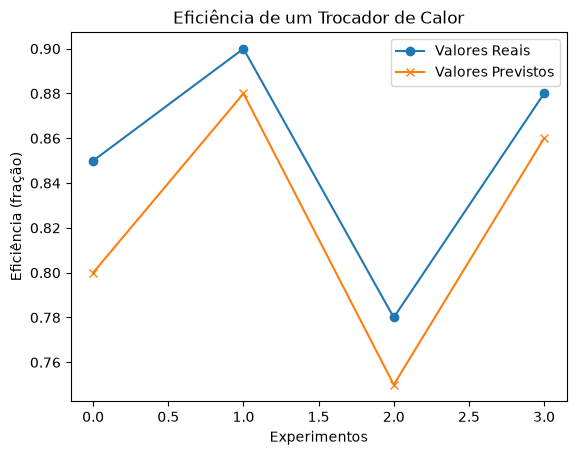

In [20]:
import matplotlib.pyplot as plt

indices = np.arange(len(y_true))

plt.plot(indices, y_true, marker='o', label="Valores Reais")
plt.plot(indices, y_pred, marker='x', label="Valores Previstos")
plt.title("Eficiência de um Trocador de Calor")
plt.xlabel("Experimentos")
plt.ylabel("Eficiência (fração)")
plt.legend()
plt.show()


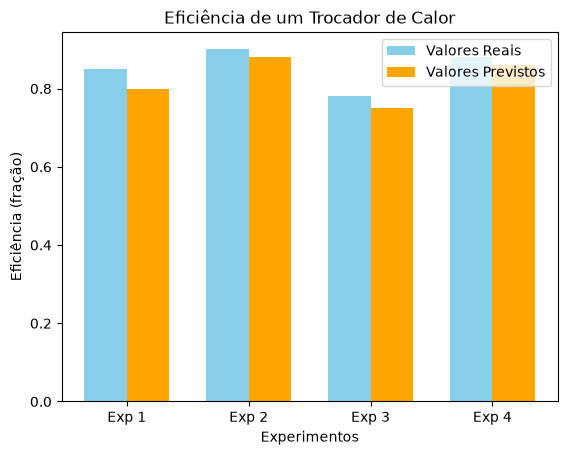

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Dados
y_true = np.array([0.85, 0.90, 0.78, 0.88])
y_pred = np.array([0.80, 0.88, 0.75, 0.86])
indices = np.arange(len(y_true))

# Gráfico de barras
width = 0.35
plt.bar(indices - width/2, y_true, width, label="Valores Reais", color="skyblue")
plt.bar(indices + width/2, y_pred, width, label="Valores Previstos", color="orange")

plt.title("Eficiência de um Trocador de Calor")
plt.xlabel("Experimentos")
plt.ylabel("Eficiência (fração)")
plt.xticks(indices, [f"Exp {i+1}" for i in indices])
plt.legend()
plt.show()


__Reflexão sobre os resultados__

- Quanto menor o MSE, mais próximo o modelo está dos valores reais.

- Em Engenharia Química, isso significa modelos mais confiáveis para prever desempenho de equipamentos (ex: colunas de destilação, trocadores de calor, reatores).

- O mesmo raciocínio pode ser aplicado em controle de processos, simulação de propriedades termodinâmicas, etc.

<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; text-align:left; color:#003366; font-size:22px; font-weight:bold; border-radius:8px; padding:15px 20px; margin-top:20px;">5. Aplicações em Engenharia Química</div>

__Exercício de Aplicação__

__Previsão de Tipo de Unidade com Redes Neurais__.

Considere os dados experimentais apresentados na tabela a seguir, que descrevem algumas unidades operacionais em uma planta química. Para cada unidade, foram registrados seu peso (em libras), sua altura (em polegadas) e o tipo da unidade (Reator ou Destilador).

<img src="img/Tab_10.png" alt="UESC" style="width: 700px; display: block; margin: 0 auto 5px auto;">
<p style="text-align: center;"><strong>Figura: Previsão de tipo de unidade com redes neurais.</strong></p>

__Cálculo feedforward:__

Etapas:

- Entrada ($x_1$, $x_2$) → Camada Oculta ($h_1$, $h_2$) → Saída ($o_1$)

__Função de Ativação a ser usada__: Sigmoid

$$\sigma(x)=\frac{1}{1+e^{-x}}.$$

__Código em Python da resolução do problema__

Época 0 - Erro quadrático médio: 0.1853
Época 100 - Erro quadrático médio: 0.1108
Época 200 - Erro quadrático médio: 0.0897
Época 300 - Erro quadrático médio: 0.0761
Época 400 - Erro quadrático médio: 0.0664
Época 500 - Erro quadrático médio: 0.0591
Época 600 - Erro quadrático médio: 0.0533
Época 700 - Erro quadrático médio: 0.0487
Época 800 - Erro quadrático médio: 0.0448
Época 900 - Erro quadrático médio: 0.0415

Pesos finais:
[[3.16510645]
 [1.47189405]]
Bias final: -2.4875276201203067
Entrada [0.5 0.5] → Probabilidade: 0.46 → Classe prevista: Reator
Entrada [0.95       0.91666667] → Probabilidade: 0.87 → Classe prevista: Destilador


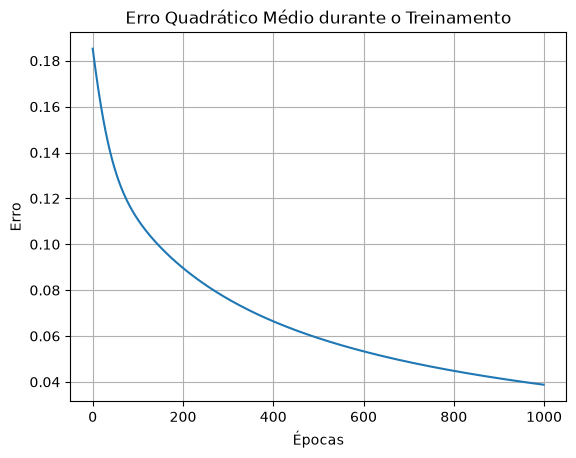

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Dados de entrada (peso e altura)
X = np.array([
    [133, 65],
    [160, 72],
    [152, 70],
    [120, 60]
], dtype=np.float64)

# Normalização min-max
X_min = X.min(axis=0)
X_max = X.max(axis=0)
X_norm = (X - X_min) / (X_max - X_min)

# Saída desejada: 0 = Reator, 1 = Destilador
y = np.array([[0], [1], [1], [0]])

# Função sigmoide e sua derivada
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivada(z):
    s = sigmoid(z)
    return s * (1 - s)

# Inicialização de pesos e bias
np.random.seed(0)
w = np.random.randn(2, 1)
b = 0.0

# Hiperparâmetros
alpha = 0.1
epocas = 1000
erros = []

# Treinamento
for epoca in range(epocas):
    z = np.dot(X_norm, w) + b
    y_pred = sigmoid(z)

    erro = y_pred - y
    custo = np.mean(erro ** 2)
    erros.append(custo)

    grad_w = 2 * np.dot(X_norm.T, erro * sigmoid_derivada(z)) / len(X_norm)
    grad_b = 2 * np.mean(erro * sigmoid_derivada(z))

    w -= alpha * grad_w
    b -= alpha * grad_b

    if epoca % 100 == 0:
        print(f"Época {epoca} - Erro quadrático médio: {custo:.4f}")

# Pesos e bias finais
print("\nPesos finais:")
print(w)
print("Bias final:", b)

# Teste com novas entradas
novas_entradas = np.array([
    [140, 66],
    [158, 71]
], dtype=np.float64)

novas_entradas_norm = (novas_entradas - X_min) / (X_max - X_min)

for entrada in novas_entradas_norm:
    z = np.dot(entrada, w) + b
    prob = sigmoid(z)
    classe = "Destilador" if prob >= 0.5 else "Reator"
    print(f"Entrada {entrada} → Probabilidade: {prob[0]:.2f} → Classe prevista: {classe}")

# Gráfico do erro quadrático médio
plt.plot(erros)
plt.title("Erro Quadrático Médio durante o Treinamento")
plt.xlabel("Épocas")
plt.ylabel("Erro")
plt.grid(True)
plt.show()

__Como interpretar o gráfico de erro__.

1. Tendência decrescente: Se o erro vai diminuindo ao longo das épocas, significa que a rede neural está aprendendo.
2. Estabilização do erro: Quando o gráfico começa a se estabilizar, é um indicativo de que o modelo convergiu.
3. __Oscilações__:
   - Se o gráfico oscila demais, pode ser que a taxa de aprendizado (alpha) esteja alta.
   - Se o erro não diminui muito ou fica quase constante desde o início, talvez seja necessário ajustar os pesos iniciais ou rever a normalização dos dados.
4. __Possíveis melhorias__:
   - Testar com mais dados.
   - Aumentar o número de neurônios (caso avance para modelos com camadas ocultas).
   - Aumentar o número de neurônios (caso avance para modelos com camadas ocultas).

__Usando bibliotecas específicass__

Podemos usar bibliotecas específicas tais como __scikit-learn__,__TensorFlow__  e __keras__ para resolver o mesmo problema. E observe que as linhas de código diminuem muito com o uso dessas biblitecas prontas o que possibilita a obtenção rápida e segura dos resultados.
**Atenção:** o exemplo seguinte utiliza pesos definidos manualmente e executa somente a propagação direta (*feedforward*); não há treinamento do modelo.


In [23]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
import matplotlib.pyplot as plt

# Dados brutos: Peso (lb), Altura (pol)
dados = np.array([
    [133, 65],  # Reator
    [160, 72],  # Destilador
    [152, 70],  # Destilador
    [120, 60]   # Reator
])

# Saída desejada: 0 para Reator, 1 para Destilador
saidas = np.array([0, 1, 1, 0])

# Normalização dos dados de entrada com MinMaxScaler
scaler = MinMaxScaler()
entradas_normalizadas = scaler.fit_transform(dados)

# Visualizando os dados normalizados
print("Entradas normalizadas:\n", entradas_normalizadas)

# Criação da rede neural (sem treinamento)
modelo = Sequential([
    Input(shape=(2,)),
    Dense(2, activation='sigmoid', name='camada_oculta'),
    Dense(1, activation='sigmoid', name='camada_saida')
])

# Fornecimento manual dos pesos e bias (didático)
pesos_ocultos = np.array([[0.5, -0.4], [-0.3, 0.8]])  # shape: (2, 2)
bias_ocultos = np.array([0.1, -0.2])                 # shape: (2,)

pesos_saida = np.array([[1.2], [-1.0]])              # shape: (2, 1)
bias_saida = np.array([0.05])                        # shape: (1,)

# Atribuir os pesos manualmente às camadas
modelo.get_layer('camada_oculta').set_weights([pesos_ocultos, bias_ocultos])
modelo.get_layer('camada_saida').set_weights([pesos_saida, bias_saida])

# Realizando as previsões (feedforward)
saidas_preditas = modelo.predict(entradas_normalizadas)

# Mostrar os resultados
for i, saida in enumerate(saidas_preditas):
    print(f"Unidade {chr(65+i)}: Probabilidade de ser Destilador = {saida[0]:.4f}")

Entradas normalizadas:
 [[0.325      0.41666667]
 [1.         1.        ]
 [0.8        0.83333333]
 [0.         0.        ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Unidade A: Probabilidade de ser Destilador = 0.5474
Unidade B: Probabilidade de ser Destilador = 0.5472
Unidade C: Probabilidade de ser Destilador = 0.5469
Unidade D: Probabilidade de ser Destilador = 0.5572


__Gráfico de visualização (opcional)__

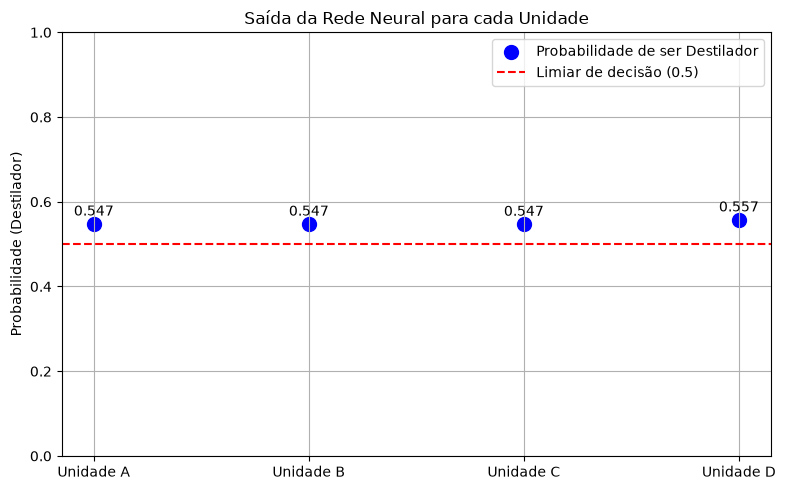

In [24]:
plt.figure(figsize=(8, 5))
x_labels = ['Unidade A', 'Unidade B', 'Unidade C', 'Unidade D']
valores_saida = saidas_preditas.flatten()

# Gráfico de dispersão (pontos)
plt.scatter(x_labels, valores_saida, color='blue', s=100, label='Probabilidade de ser Destilador')

# Linha de decisão em 0.5
plt.axhline(y=0.5, color='red', linestyle='--', label='Limiar de decisão (0.5)')

# Adiciona valores numéricos acima dos pontos
for i, valor in enumerate(valores_saida):
    plt.text(i, valor + 0.02, f'{valor:.3f}', ha='center', fontsize=10)

plt.ylim(0, 1)
plt.title('Saída da Rede Neural para cada Unidade')
plt.ylabel('Probabilidade (Destilador)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

<div style="text-align: center; font-size: 12px; color: gray;
            margin-top: 40px; padding-top: 15px;
            border-top: 1px solid #dddddd;">

  Material desenvolvido pelo Grupo de Pesquisas em
  Modelagem Computacional da UESC.<br>

  © 2026 — Todos os direitos reservados.
  Uso comercial somente mediante autorização.

</div>